In [5]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw.csv")
df.head(20)

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...
5,BI,can you help me cancel order {{Order Number}}?,ORDER,cancel_order,"Of course, I'm here to assist you in canceling..."
6,BCLN,"I can no longer afford order {{Order Number}},...",ORDER,cancel_order,I pick up what you're putting down that you're...
7,BL,I am trying to cancel purchase {{Order Number}},ORDER,cancel_order,I've understood that you're seeking assistance...
8,BL,I have got to cancel purchase {{Order Number}},ORDER,cancel_order,I'm sensitive to the fact that you're seeking ...
9,BLQ,i need help canceling purchase {{Order Number}},ORDER,cancel_order,I perceive that you're seeking assistance with...


In [13]:
df.shape

(26872, 5)

<Axes: xlabel='count', ylabel='category'>

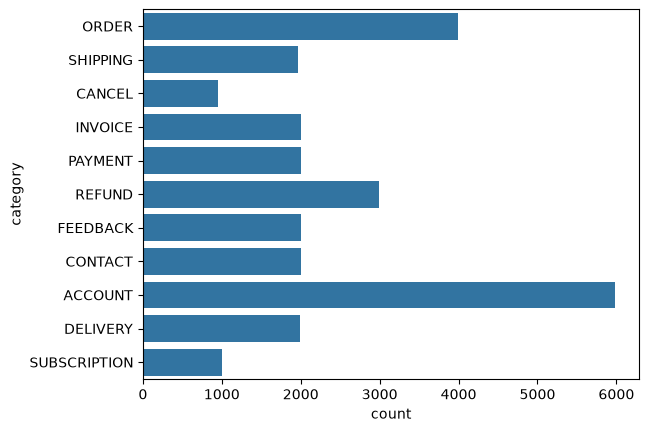

In [19]:
sns.countplot(data=df, y="category")

In [22]:
df["flags"].value_counts()

flags
BL        5212
BLQ       2467
BIL       2138
BLM       1297
BILQ      1057
          ... 
BIPQWZ       1
BENQWZ       1
BPQWZ        1
BKQZ         1
BELMNW       1
Name: count, Length: 394, dtype: int64

<Axes: xlabel='instruction'>

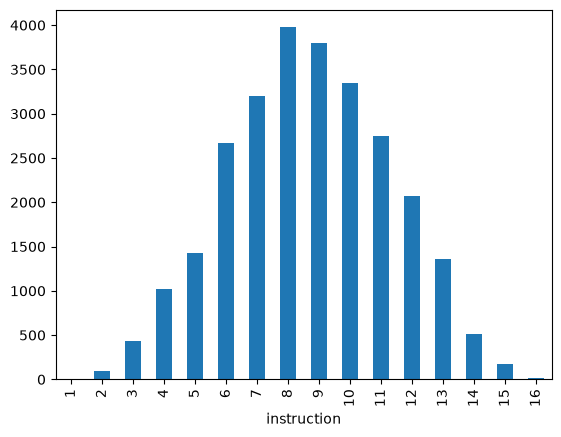

In [12]:
df["instruction"].apply(lambda x: len(x.split())).value_counts().sort_index().plot(kind="bar")

In [17]:
df["intent"].value_counts()

intent
check_invoice               1000
complaint                   1000
contact_customer_service    1000
edit_account                1000
switch_account              1000
check_payment_methods        999
contact_human_agent          999
delivery_period              999
get_invoice                  999
newsletter_subscription      999
payment_issue                999
registration_problems        999
cancel_order                 998
place_order                  998
track_refund                 998
change_order                 997
check_refund_policy          997
create_account               997
get_refund                   997
review                       997
set_up_shipping_address      997
delete_account               995
delivery_options             995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64

In [30]:
dups = df[df.duplicated("instruction", keep=False)]
dups.groupby("instruction")["category"].nunique().max()

np.int64(1)

In [23]:
for msg in df.sample(15, random_state=42)["instruction"]:
    print(msg)


I can't talk with  a human agent
I have got to locate hte bills from {{Person Name}}
I cannot pay, help me to inform of a problem with payments
I want help speaking to customer service
I try to see th accepted payment options
where to sign up to the company nmewsletter
I'd like to see the withdrwaal fee how can i do it
I want to speak with someone
can you help me getting bill #85632?
I don't know how to take a quick look at invoice #12588
I don't know how to delete my platinum account
help me check in what cases can I ask to be refunded
is it possible to locate my bill from {{Person Name}}
i want help to file a consumer claim against ur organization
uhave a free number to call customer support


In [7]:
import sys
sys.path.append("..")
from src.preprocess import prepare_data

df_clean = prepare_data(df)

dups = df_clean[df_clean.duplicated("text", keep=False)]
dups.groupby("text")["category"].nunique().max()

print(len(dups))
print(len(df) - len(df_clean))

0
3045
